In [1]:
from __future__ import annotations

from typing import Any, Callable, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import cm
from matplotlib.colors import Normalize

import spacecore as sc

In [2]:
def as_numpy(x):
    if hasattr(x, "detach"):
        return x.detach().cpu().numpy()
    return np.asarray(x)


def scalar_value(x) -> float:
    return float(as_numpy(x).item())


class RiemannianManifoldSpace(sc.VectorSpace):
    """Vector-backed Riemannian manifold base class."""

    def retract(self, x: Any, v: Any) -> Any:
        raise NotImplementedError("Subclasses must implement retract(x, v).")

    def proj_tangent(self, x: Any, v: Any) -> Any:
        return v

    def metric(self, x: Any, u: Any, v: Any) -> Any:
        return super().inner(u, v)

    def tangent_norm(self, x: Any, v: Any) -> Any:
        return self.ops.sqrt(self.ops.real(self.metric(x, v, v)))

    def zero_tangent(self, x: Any) -> Any:
        return self.zeros()

    def riemannian_grad(self, x: Any, euclidean_grad: Any) -> Any:
        return self.proj_tangent(x, euclidean_grad)

    def parallel_transport(self, x: Any, y: Any, v: Any) -> Any:
        return self.proj_tangent(y, v)

In [3]:
class RiemannianGradientDescentResult(NamedTuple):
    x: Any
    converged: bool
    num_iters: int
    final_grad_norm: float
    trajectory: tuple[Any, ...]
    values: tuple[float, ...]


def riemannian_gradient_descent(
    manifold: RiemannianManifoldSpace,
    objective: Callable[[Any], Any],
    x0: Any,
    *,
    grad: Callable[[Any], Any] | None = None,
    step_size: float = 1.0,
    maxiter: int = 100,
    tol: float = 1e-8,
    line_search: bool = False,
    backtracking: float = 0.5,
    armijo: float = 1e-4,
    min_step_size: float = 1e-12,
    record_trajectory: bool = False,
) -> RiemannianGradientDescentResult:
    if grad is None:
        if hasattr(objective, "riemannian_grad"):
            grad = objective.riemannian_grad
        elif hasattr(objective, "grad"):
            grad = objective.grad
        else:
            raise ValueError("Pass grad=... or provide objective.grad/riemannian_grad.")

    x = x0
    trajectory = [x] if record_trajectory else []
    values = [scalar_value(objective(x))] if record_trajectory else []
    converged = False
    num_iters = 0

    for iteration in range(maxiter):
        g = grad(x)
        grad_norm = scalar_value(manifold.tangent_norm(x, g))
        if grad_norm <= tol:
            converged = True
            break

        eta = step_size
        f_x = scalar_value(objective(x)) if line_search else None
        while True:
            candidate = manifold.retract(x, manifold.scale(-eta, g))
            if not line_search:
                break

            f_candidate = scalar_value(objective(candidate))
            if f_candidate <= f_x - armijo * eta * grad_norm**2:
                break
            eta *= backtracking
            if eta < min_step_size:
                break

        x = candidate
        num_iters = iteration + 1
        if record_trajectory:
            trajectory.append(x)
            values.append(scalar_value(objective(x)))

    final_grad_norm = scalar_value(manifold.tangent_norm(x, grad(x)))
    converged = converged or final_grad_norm <= tol
    return RiemannianGradientDescentResult(
        x=x,
        converged=converged,
        num_iters=num_iters,
        final_grad_norm=final_grad_norm,
        trajectory=tuple(trajectory),
        values=tuple(values),
    )

In [4]:
class TorusSpace(RiemannianManifoldSpace):
    """Embedded torus parameterized by angles ``(u, v)`` in ``[0, 2π)^2``.

    The optimization variable is ``theta = (u, v)``.  The displayed point is

        Φ(u, v) = ((R + r cos(v)) cos(u), (R + r cos(v)) sin(u), r sin(v)).

    The metric is the induced diagonal metric

        ds² = (R + r cos(v))² du² + r² dv².
    """

    def __init__(
        self,
        major_radius: float = 2.0,
        minor_radius: float = 0.75,
        ctx: sc.Context | str | None = None,
    ):
        super().__init__((2,), ctx)
        self.R = float(major_radius)
        self.r = float(minor_radius)

    def retract(self, x, v):
        return self.ctx.asarray(np.mod(as_numpy(x) + as_numpy(v), 2 * np.pi))

    def metric(self, x, u, v):
        x_np = as_numpy(x)
        u_np = as_numpy(u)
        v_np = as_numpy(v)
        minor_angle = x_np[..., 1]
        E = (self.R + self.r * np.cos(minor_angle)) ** 2
        G = self.r**2
        return self.ctx.asarray(E * u_np[..., 0] * v_np[..., 0] + G * u_np[..., 1] * v_np[..., 1])

    def sharp(self, x, covector):
        """Raise a covector using the inverse induced metric."""
        x_np = as_numpy(x)
        cov_np = as_numpy(covector)
        minor_angle = x_np[..., 1]
        E = (self.R + self.r * np.cos(minor_angle)) ** 2
        G = self.r**2
        grad = np.stack([cov_np[..., 0] / E, cov_np[..., 1] / G], axis=-1)
        return self.ctx.asarray(grad)

    def embed(self, theta):
        theta_np = as_numpy(theta)
        u = theta_np[..., 0]
        v = theta_np[..., 1]
        radius = self.R + self.r * np.cos(v)
        xyz = np.stack(
            [radius * np.cos(u), radius * np.sin(u), self.r * np.sin(v)],
            axis=-1,
        )
        return xyz


class TorusObjective:
    """Nonconvex objective on the embedded torus.

    The terms mix several Fourier modes with one localized attractive well.  This
    gives a heatmap with ridges, saddles, and multiple basins rather than a nearly
    linear color gradient.
    """

    def __init__(self, manifold: TorusSpace, well_center=(5.0, 0.75)):
        self.manifold = manifold
        self.well_center = np.asarray(well_center, dtype=float)

    def _value_np(self, theta_np):
        u = theta_np[..., 0]
        v = theta_np[..., 1]
        u0, v0 = self.well_center
        well = np.exp(1.4 * (np.cos(u - u0) + np.cos(v - v0) - 2.0))
        return (
            0.65 * np.cos(3.0 * u - 2.0 * v)
            + 0.35 * np.sin(5.0 * v + 0.7)
            + 0.55 * np.sin(2.0 * u + v)
            + 0.25 * np.cos(4.0 * u) * np.sin(3.0 * v)
            - 1.25 * well
            + 0.15 * np.cos(6.0 * u - 4.0 * v)
        )

    def _partial_np(self, theta_np):
        u = theta_np[..., 0]
        v = theta_np[..., 1]
        u0, v0 = self.well_center
        well = np.exp(1.4 * (np.cos(u - u0) + np.cos(v - v0) - 2.0))

        df_du = (
            -1.95 * np.sin(3.0 * u - 2.0 * v)
            + 1.10 * np.cos(2.0 * u + v)
            - 1.00 * np.sin(4.0 * u) * np.sin(3.0 * v)
            + 1.75 * well * np.sin(u - u0)
            - 0.90 * np.sin(6.0 * u - 4.0 * v)
        )
        df_dv = (
            1.30 * np.sin(3.0 * u - 2.0 * v)
            + 1.75 * np.cos(5.0 * v + 0.7)
            + 0.55 * np.cos(2.0 * u + v)
            + 0.75 * np.cos(4.0 * u) * np.cos(3.0 * v)
            + 1.75 * well * np.sin(v - v0)
            + 0.60 * np.sin(6.0 * u - 4.0 * v)
        )
        return np.stack([df_du, df_dv], axis=-1)

    def __call__(self, theta):
        return self.manifold.ctx.asarray(self._value_np(as_numpy(theta)))

    def coordinate_grad(self, theta):
        """Gradient covector ``(∂f/∂u, ∂f/∂v)`` in torus coordinates."""
        return self.manifold.ctx.asarray(self._partial_np(as_numpy(theta)))

    def riemannian_grad(self, theta):
        return self.manifold.sharp(theta, self.coordinate_grad(theta))

In [5]:
ctx = sc.Context(sc.NumpyOps(), dtype="float64")
torus = TorusSpace(major_radius=2.0, minor_radius=0.75, ctx=ctx)
obj = TorusObjective(torus, well_center=(5.0, 0.75))

# Coordinates (u, v) on the torus.  This starts outside the main basin so that
# the descent path crosses a visible part of the heatmap.
theta0 = ctx.asarray([5.6, 1.2])

result = riemannian_gradient_descent(
    manifold=torus,
    objective=obj,
    x0=theta0,
    step_size=0.3,
    maxiter=160,
    tol=1e-6,
    line_search=True,
    record_trajectory=True,
)

final_xyz = torus.embed(result.x)
print(f"Converged: {result.converged} in {result.num_iters} iterations")
print(f"Final gradient norm: {result.final_grad_norm:.2e}")
print(f"Initial objective: {result.values[0]:.6f}")
print(f"Final objective: {result.values[-1]:.6f}")
print(f"Final torus coordinates (u, v): {as_numpy(result.x)}")
print(f"Final embedded point: {final_xyz}")

Converged: True in 102 iterations
Final gradient norm: 8.27e-07
Initial objective: -0.997999
Final objective: -2.541454
Final torus coordinates (u, v): [5.38521095 0.68911921]
Final embedded point: [ 1.60713053 -2.01683501  0.47689322]


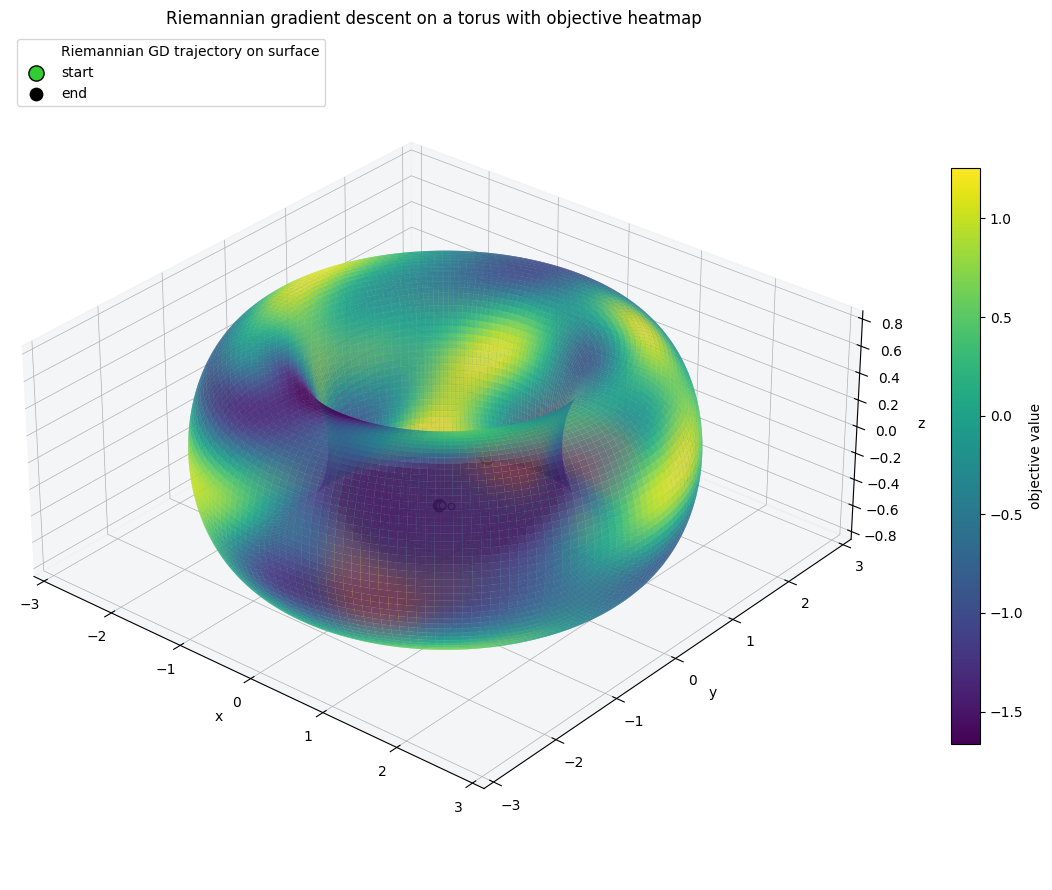

In [18]:
def torus_normal(torus: TorusSpace, theta):
    """Unit normal of the standard torus embedding at ``theta = (u, v)``."""
    theta_np = as_numpy(theta)
    u = theta_np[..., 0]
    v = theta_np[..., 1]
    return np.stack(
        [np.cos(v) * np.cos(u), np.cos(v) * np.sin(u), np.sin(v)],
        axis=-1,
    )


def unwrap_torus_trajectory(traj_theta):
    """Choose continuous angle representatives for a torus trajectory."""
    traj_theta = np.asarray(traj_theta, dtype=float)
    out = traj_theta.copy()

    for k in range(1, len(out)):
        delta = out[k] - out[k - 1]
        delta = (delta + np.pi) % (2.0 * np.pi) - np.pi
        out[k] = out[k - 1] + delta

    return out


def densify_torus_trajectory(traj_theta, points_per_segment: int = 20):
    """Interpolate in torus coordinates, then embed.

    This is important: drawing straight line segments between embedded torus
    points creates 3D chords, which can visually cut through the torus interior.
    Interpolating in the angle coordinates makes the displayed curve follow the
    surface instead.
    """
    traj_theta = unwrap_torus_trajectory(traj_theta)

    pieces = []
    for a, b in zip(traj_theta[:-1], traj_theta[1:]):
        t = np.linspace(0.0, 1.0, points_per_segment, endpoint=False)
        pieces.append((1.0 - t)[:, None] * a + t[:, None] * b)

    pieces.append(traj_theta[-1:])

    return np.concatenate(pieces, axis=0)


traj_theta = np.stack([as_numpy(theta) for theta in result.trajectory])
traj_theta_dense = densify_torus_trajectory(traj_theta, points_per_segment=24)
traj_xyz = torus.embed(traj_theta_dense)

# Torus grid.
nu = 180
nv = 90
u = np.linspace(0.0, 2.0 * np.pi, nu)
v = np.linspace(0.0, 2.0 * np.pi, nv)
U, V = np.meshgrid(u, v, indexing="ij")
theta_grid = np.stack([U, V], axis=-1)
xyz_grid = torus.embed(theta_grid)
X = xyz_grid[..., 0]
Y = xyz_grid[..., 1]
Z = xyz_grid[..., 2]

# Objective heatmap on the same parameter grid.
F = obj._value_np(theta_grid)
norm = Normalize(vmin=np.percentile(F, 2), vmax=np.percentile(F, 98))
facecolors = cm.viridis(norm(F))

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X,
    Y,
    Z,
    facecolors=facecolors,
    rstride=1,
    cstride=1,
    linewidth=0,
    antialiased=True,
    shade=False,
    alpha=0.75,
)

# Exact trajectory on the torus surface.  Keep this zero if you want the curve
# mathematically on the surface.  Increase to e.g. 0.01 only if your renderer
# hides parts of the curve because of z-fighting.
normal_offset = 0.0
traj_plot = traj_xyz + normal_offset * torus_normal(torus, traj_theta_dense)

ax.plot(
    traj_plot[::10, 0],
    traj_plot[::10, 1],
    traj_plot[::10, 2],
    color="white",
    linewidth=3.0,
    label="Riemannian GD trajectory on surface",
)

# Plot actual optimization iterates as markers, also embedded on the torus.
iter_xyz = torus.embed(traj_theta)
iter_plot = iter_xyz + normal_offset * torus_normal(torus, traj_theta)
ax.scatter(
    iter_plot[::10, 0],
    iter_plot[::10, 1],
    iter_plot[::10, 2],
    color="white",
    edgecolors="black",
    s=22,
    depthshade=False,
)

ax.scatter(
    iter_plot[0:1, 0],
    iter_plot[0:1, 1],
    iter_plot[0:1, 2],
    color="limegreen",
    edgecolors="black",
    s=120,
    depthshade=False,
    label="start",
)
ax.scatter(
    iter_plot[-1:, 0],
    iter_plot[-1:, 1],
    iter_plot[-1:, 2],
    color="black",
    edgecolors="white",
    s=120,
    depthshade=False,
    label="end",
)

mappable = cm.ScalarMappable(norm=norm, cmap="viridis")
mappable.set_array(F)
cbar = fig.colorbar(mappable, ax=ax, shrink=0.68, pad=0.08)
cbar.set_label("objective value")

ax.set_title("Riemannian gradient descent on a torus with objective heatmap")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_box_aspect((1.0, 1.0, 0.45))
ax.view_init(elev=30, azim=-50)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

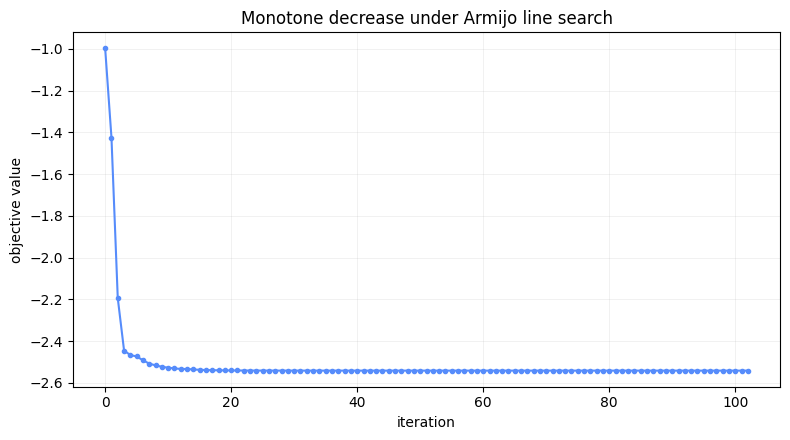

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(result.values, marker="o", markersize=3)
ax.set_xlabel("iteration")
ax.set_ylabel("objective value")
ax.set_title("Monotone decrease under Armijo line search")
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [8]:
# The optimization variable is theta = (u, v) in a torus parameter space.
# The plot uses Phi(theta), so every displayed iterate lies on the torus.
#
# The trajectory curve is densified in torus coordinates before embedding.
# Without this, matplotlib draws straight 3D chords between iterates, which can
# cut through the inside of the torus even when every iterate itself is valid.
